# 3.8 Entrenamiento robusto: ¿a qué pregunta responde su score?

🖥️ [**Diapositivas de la clase: sesión 18 (lun 9 nov)**](https://geo-smart.github.io/mlgeo-book/slides/2026/lec18_robust_training.html)

Un score de validación solo significa algo cuando sabemos qué tienen en común los datos de validación con los de entrenamiento. Los datos de la Tierra comparten mucho: mañana se parece a hoy, las celdas de malla vecinas comparten un clima y todas las estaciones registran el mismo sismo. Si se mezclan esas muestras entre los pliegues, cada muestra de validación conserva parientes cercanos en el entrenamiento, y el score mide cuánto recuerda el modelo a esos parientes. Este notebook de Jupyter (cuaderno) mide ese efecto tres veces: en una serie de tiempo, en un mapa y en una tabla de registros de sismos.

*Laboratorio. Se empieza en clase el lunes 9 de noviembre y se termina en casa. Entrega individual en Canvas, a más tardar el **lunes 16 de noviembre a las 23:59** (vea el final de este notebook).*

**Resultados de aprendizaje.** Al terminar este notebook, usted podrá:

1. comparar una división mezclada con una división que entrena con el pasado y valida con el futuro;
2. poner un score junto a un modelo de referencia (*baseline*) que no requiere aprendizaje;
3. distinguir una decisión de entrenamiento que mejora la generalización de una que solo hace un ajuste fino del score;
4. construir bloques espaciales e interpretar cómo cambia un score con el tamaño del bloque;
5. mantener todos los registros de un evento a un solo lado de la división;
6. elegir la división que corresponde al lugar donde se usará su modelo.

**Tiempo:** unos 25 minutos en parejas. Las Partes 3 y 5 son opcionales.

## Cómo funciona este notebook

Cada celda **Su turno** pide unas pocas líneas de código. Lea la pista, escriba su respuesta donde lo indica la celda y ejecútela. La celda de abajo contiene una solución desarrollada, oculta hasta que haga clic en ⋯. Esa celda oculta también comprueba su respuesta: imprime `correct` o una pista, y si su respuesta falta o es distinta, usa el resultado de referencia para que el resto del notebook siga funcionando. Su propia respuesta, si es distinta, se conserva con el mismo nombre seguido de `_yours`.

In [1]:
# Data handling
import hashlib
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr

# Plotting
import matplotlib.pyplot as plt

# Models, splits and scores (scikit-learn)
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupKFold, KFold, TimeSeriesSplit, cross_val_predict, cross_val_score

Los valores siguientes se usan en varios lugares, así que se definen una sola vez. Los colores de las figuras se distinguen también para personas con daltonismo (la paleta Okabe-Ito).

In [2]:
SEED = 42
BLOCK_SIZES = [2, 4, 6]            # Part 2: edge of a spatial block, in degrees
BLUE, ORANGE, GREEN, RED, GRAY, MUTED = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#b8b1a4", "#6e675c"
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

In [3]:
# Helper: compare an answer with a reference. If the answer is missing or different, print a hint and use the
# reference so the cells below still run; a different answer is kept as <name>_yours.
def check(name, ns, reference, hint, measure=None, tol=1e-3):
    measure = measure or (lambda value: np.asarray(value, dtype=float))
    yours = ns.get(name)
    if yours is None or (hasattr(yours, "__len__") and len(yours) == 0):
        print(f"{name}: not answered yet. Hint: {hint}\n  Using the reference result below.")
    else:
        try:
            ok = np.allclose(measure(yours), measure(reference), atol=tol)
        except Exception:
            ok = False
        if ok:
            print(f"{name}: correct")
            return
        print(f"{name}: not the expected result. Hint: {hint}\n  Your answer is kept as {name}_yours; "
              "the reference is used below.")
        ns[f"{name}_yours"] = yours
    ns[name] = reference

In [4]:
# Helper: find a course file beside the book, or fetch it from GitHub, and verify it.
BASE_URL = "https://raw.githubusercontent.com/geo-smart/mlgeo-book/main/book/"
FINGERPRINTS = {
    "Chapter1-GettingStarted/data/gps_P395_relative_position.csv": "eb22473bbc5565caafbfe1b3b539c65cf88ba3cb23dec07106d81738957a4ff6",
    "Chapter2-DataManipulation/snapshots/naturalearth_pnw_map.csv": "7ed9da2e9ac642e9bc39c9d966df9b63bf169d3819ea9c588c56211b59601791",
    "Chapter2-DataManipulation/snapshots/cpc_soilw_precl_westUS_1991-2020.nc": "7c8fda8209cfb8cc5fc4c3181382c64b56c2a8ff7971302b689bc4ec8fcf9d7b",
    "Chapter2-DataManipulation/snapshots/cpc_westUS_static_1991-2020.nc": "a9108d71d264a3767fe6642f2af69afc332c8fe56743ab4598c216b10775671a",
}


def course_file(relative):
    path = Path("..") / relative
    if not path.exists():
        path = Path(Path(relative).name)
        if not path.exists():
            urllib.request.urlretrieve(BASE_URL + relative, path)
    if hashlib.sha256(path.read_bytes()).hexdigest() != FINGERPRINTS[relative]:
        raise ValueError(f"{path} is not the course copy. Delete it, or restore it with git, and run this cell again.")
    return path

## Parte 1. Tiempo: ¿dónde estará una estación GNSS el próximo mes?

*Datos:* 📍 Sensor in situ · 🪨 Tierra sólida · 📐 Geodesia

**P395** se encuentra en la cordillera costera de Oregón, sobre la zona de subducción de Cascadia, a 45.0223°N, 123.8575°W (lista de estaciones de NGL, como en [1.7](../Chapter1-GettingStarted/1.7_get_geodetic_gnss.ipynb)). Su posición diaria hacia el este se mueve a −6.4 mm/año en el marco IGS20 (NGL MIDAS, también en 1.7): movimiento de placas y deformación en el límite de placas, con oscilaciones estacionales superpuestas. El registro va de 2006 a 2026.

In [5]:
gnss = pd.read_csv(course_file("Chapter1-GettingStarted/data/gps_P395_relative_position.csv"))
east = gnss["east_m"].to_numpy() * 1000   # mm, relative to the first day
year = gnss["decimal_year"].to_numpy()

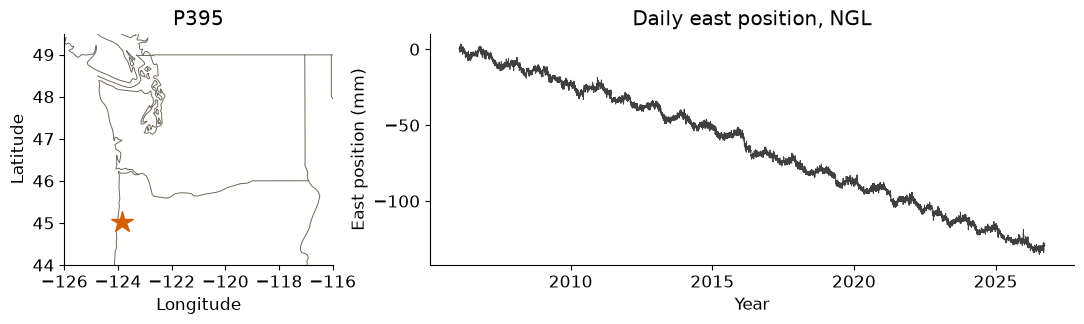

In [6]:
# Helper: where the station is, and its record.
def plot_station():
    coast = pd.read_csv(course_file("Chapter2-DataManipulation/snapshots/naturalearth_pnw_map.csv"))
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4), width_ratios=[1, 2.4])
    for _, part in coast[coast["part"] >= 0].groupby(["kind", "part"]):
        left.plot(part["lon"], part["lat"], color=MUTED, lw=0.7)
    left.plot(-123.8575, 45.0223, "*", ms=16, color=RED)
    left.set(xlim=(-126, -116), ylim=(44, 49.5), xlabel="Longitude", ylabel="Latitude", title="P395")
    right.plot(year, east, color="0.25", lw=0.7)
    right.set(xlabel="Year", ylabel="East position (mm)", title="Daily east position, NGL")
    plt.tight_layout()
    plt.show()


plot_station()

**La tarea.** A partir de los últimos 60 días, prediga la posición media de los próximos 30 días. Construimos una muestra cada 5 días. Las muestras vecinas comparten 55 de sus 60 días de historia y 25 de sus 30 días objetivo, lo que las hace fuertemente correlacionadas por construcción, como ocurre con cualquier serie dividida en ventanas.

In [7]:
history, horizon, stride = 60, 30, 5
rows = []
for i in range(history, len(east) - horizon, stride):
    past = east[i - history:i]
    rows.append({"mean_60d": past.mean(), "mean_10d": east[i - 10:i].mean(), "last": east[i - 1],
                 "slope_60d": np.polyfit(np.arange(history), past, 1)[0],
                 "season_sin": np.sin(2 * np.pi * year[i]), "season_cos": np.cos(2 * np.pi * year[i]),
                 "target": east[i:i + horizon].mean(), "year": year[i]})
samples = pd.DataFrame(rows)
FEATURES = ["mean_60d", "mean_10d", "last", "slope_60d", "season_sin", "season_cos"]
X_time, y_time = samples[FEATURES].to_numpy(), samples["target"].to_numpy()
last_value = samples["last"].to_numpy()
GAP = horizon // stride   # samples left out between training and validation, so target windows do not overlap
print(f"{len(samples)} samples, {X_time.shape[1]} features")
samples.head(3)

1482 samples, 6 features


,mean_60d,mean_10d,last,slope_60d,season_sin,season_cos,target,year
0,0.258317,-0.0446,-0.951,-0.017466,0.993105,0.117225,-2.334767,2006.2313
1,0.109367,-0.8279,-1.616,-0.028743,0.999507,0.031411,-2.681533,2006.2450
2,0.113650,-0.8473,-0.883,-0.036120,0.998506,-0.054636,-3.296500,2006.2587


En todas las pruebas de abajo se usa el mismo bosque aleatorio, así que cualquier cambio en el score proviene de cómo dividimos las muestras.

### Su turno (1): una división mezclada

**Pregunta:** ¿pronostica bien el bosque la posición media de 30 días para muestras con las que no fue entrenado?

Apartamos algunas muestras, entrenamos con el resto y comparamos los pronósticos del bosque con las medias reales de 30 días de las muestras apartadas. `cross_val_score` realiza esta prueba como una secuencia de pasos, repetida cinco veces para que cada muestra quede apartada exactamente una vez:

1. mezclar las muestras y cortarlas en 5 pliegues;
2. entrenar con 4 pliegues y pronosticar el 5.º, el pliegue de validación;
3. promediar el tamaño de los fallos, |pronóstico − valor real|, sobre las muestras de validación: el error absoluto medio (MAE), en mm;
4. pasar al siguiente pliegue y repetir los pasos 2 y 3.

Guarde la media de los cinco MAE en `shuffled_mae`. Se lee como el fallo típico de un pronóstico, así que cuanto menor, mejor.

*Pista:* `-cross_val_score(forest, X_time, y_time, cv=shuffled, scoring="neg_mean_absolute_error").mean()`. El signo menos está ahí porque scikit-learn devuelve el error con signo negativo, para que mayor sea siempre mejor.

In [8]:
forest = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
shuffled = KFold(n_splits=5, shuffle=True, random_state=SEED)

shuffled_mae = None   # replace None with your expression

*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [9]:
shuffled_mae_sol = -cross_val_score(forest, X_time, y_time, cv=shuffled, scoring="neg_mean_absolute_error").mean()
check("shuffled_mae", globals(), shuffled_mae_sol, "use cv=shuffled in cross_val_score, with the minus sign in front.", tol=0.01)
print(f"Forest, shuffled folds: {shuffled_mae:.2f} mm")

shuffled_mae: not answered yet. Hint: use cv=shuffled in cross_val_score, with the minus sign in front.
  Using the reference result below.
Forest, shuffled folds: 0.46 mm


In [ ]:
# What cross_val_score does, written out: the same five folds, each forest fit and scored by hand.
shuffled_mae_by_hand = np.mean([
    mean_absolute_error(
        y_time[val],
        RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1)
        .fit(X_time[train], y_time[train])
        .predict(X_time[val])
    )
    for train, val in shuffled.split(X_time)
])

In [ ]:
print(f"By hand: {shuffled_mae_by_hand:.2f} mm. cross_val_score: {shuffled_mae:.2f} mm. Same folds, same forests.")

### Su turno (2): entrenar con el pasado, validar con el futuro

**Pregunta:** ¿qué tan bien pronostica el bosque días posteriores a todo aquello con lo que fue entrenado? Así es como se usa un pronóstico.

`future` sigue la misma secuencia de pasos, pero cada pliegue de validación es posterior a todas sus muestras de entrenamiento, y `gap` descarta las muestras intermedias cuyas ventanas de 30 días se solaparían. Calcule el MAE medio sobre estos pliegues y guárdelo en `future_mae`.

*Pista:* solo cambia el argumento `cv`.

In [10]:
future = TimeSeriesSplit(n_splits=5, gap=GAP)

future_mae = None   # replace None with your expression

*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [11]:
future_mae_sol = -cross_val_score(forest, X_time, y_time, cv=future, scoring="neg_mean_absolute_error").mean()
check("future_mae", globals(), future_mae_sol, "same call as before, with cv=future.", tol=0.01)
print(f"Forest, future folds:   {future_mae:.1f} mm")

future_mae: not answered yet. Hint: same call as before, with cv=future.
  Using the reference result below.
Forest, future folds:   12.4 mm


### Su turno (3): un modelo de referencia que no requiere aprendizaje

**Pregunta:** ¿supera el bosque a una regla que no aprende nada?

La **persistencia** pronostica que los próximos 30 días estarán donde estaba la estación el último día observado, `last_value`. En los mismos pliegues de validación futuros, calcule el MAE de este pronóstico frente a las medias reales de 30 días y luego la media sobre los pliegues. Guarde el resultado en `persistence_mae`.

*Pista:* `np.mean([mean_absolute_error(y_time[v], last_value[v]) for _, v in future.split(X_time)])`.

In [12]:
persistence_mae = None   # replace None with your expression

*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [13]:
persistence_mae_sol = np.mean([mean_absolute_error(y_time[v], last_value[v]) for _, v in future.split(X_time)])
check("persistence_mae", globals(), persistence_mae_sol, "loop over future.split(X_time) and keep only the validation indices.", tol=0.01)
line_mae = -cross_val_score(LinearRegression(), X_time, y_time, cv=future, scoring="neg_mean_absolute_error").mean()
print(pd.Series({"forest, shuffled folds": shuffled_mae, "forest, future folds": future_mae,
                 "persistence, future folds": persistence_mae, "linear regression, future folds": line_mae}).round(2).to_string())

persistence_mae: not answered yet. Hint: loop over future.split(X_time) and keep only the validation indices.
  Using the reference result below.
forest, shuffled folds              0.46
forest, future folds               12.38
persistence, future folds           1.17
linear regression, future folds     0.82


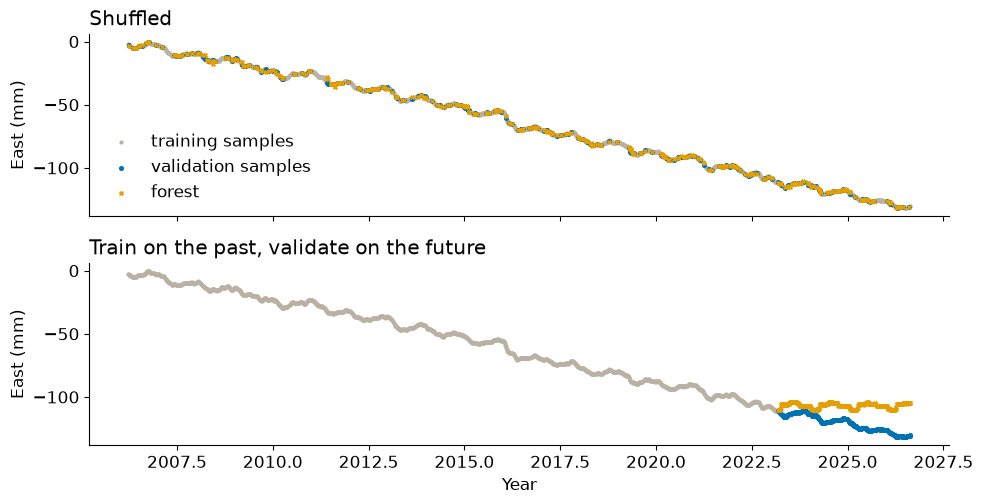

In [14]:
# Helper: one fold of each split, with the forest's predictions.
def plot_two_splits():
    fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True, sharey=True)
    for ax, split, title in [(axes[0], shuffled, "Shuffled"), (axes[1], future, "Train on the past, validate on the future")]:
        fit, val = list(split.split(X_time))[-1]
        predicted = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1).fit(X_time[fit], y_time[fit]).predict(X_time[val])
        ax.scatter(samples["year"].iloc[fit], y_time[fit], s=4, color=GRAY, label="training samples")
        ax.scatter(samples["year"].iloc[val], y_time[val], s=7, color=BLUE, label="validation samples")
        ax.scatter(samples["year"].iloc[val], predicted, s=7, color=ORANGE, marker="x", label="forest")
        ax.set(ylabel="East (mm)")
        ax.set_title(title, loc="left")
    axes[0].legend(frameon=False, loc="lower left")
    axes[1].set_xlabel("Year")
    plt.tight_layout()
    plt.show()


plot_two_splits()

**Haga una pausa y discuta.**

- ¿Por qué se aplana el bosque en el panel inferior? (La diapositiva del viernes sobre los días calurosos muestra el mismo efecto.)
- El score de la división mezclada está por debajo de 1 mm. ¿Qué hizo el bosque para obtenerlo?
- La regresión lineal y la persistencia no requieren ningún ajuste de configuración. ¿Qué propiedad física de este registro aprovechan?

:::{dropdown} Puntos a destacar
Un bosque solo puede devolver promedios de valores de entrenamiento, así que no puede predecir posiciones fuera del rango que ha visto, y esta estación sigue moviéndose. En la división mezclada, cada muestra de validación tiene vecinas en el entrenamiento que comparten la mayoría de sus 60 días, de modo que el bosque las copia. La persistencia y el modelo lineal aprovechan ambos que la posición cambia de forma lenta y constante. Aquí un modelo flexible pierde contra una regla de una línea, algo que nunca se aprendería con el score de la división mezclada.
:::

### ¿Qué decisiones de entrenamiento importan?

Hasta ahora solo cambió la división. Ahora cambiamos el entrenamiento mismo y juzgamos cada decisión con dos scores: los pliegues mezclados, lo que mostraría un informe sin verificar, y los pliegues futuros, el uso real del pronóstico de esta estación. Un error menor en los pliegues futuros es una mejor **generalización**. Una pequeña mejora obtenida al ajustar configuraciones (hiperparámetros), con el mismo modelo y las mismas variables, es un **ajuste fino**; no es el ajuste fino (*fine-tuning*) de una red preentrenada del capítulo 4.

### Su turno (4): ajustar el bosque

**Pregunta:** ¿pueden mejores configuraciones corregir el pronóstico del bosque?

`SETTINGS` enumera seis bosques: profundidad máxima 3, 12 o ilimitada, y al menos 1 o 20 muestras por hoja. Para cada uno, calcule el MAE en pliegues mezclados y en pliegues futuros, como en Su turno (1) y (2). Reúnalos en `tuning`, una tabla con una fila por configuración y las columnas `shuffled` y `future`.

*Pista:* `pd.DataFrame([{**setting, "shuffled": ..., "future": ...} for setting in SETTINGS])`, donde cada `...` es la llamada de Su turno (1) con `RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1, **setting)` y el `cv` correspondiente.

In [15]:
SETTINGS = [{"max_depth": depth, "min_samples_leaf": leaf} for depth in (3, 12, None) for leaf in (1, 20)]

tuning = None   # replace None with your table

*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [16]:
def forest_mae(setting, cv):
    model = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1, **setting)
    return -cross_val_score(model, X_time, y_time, cv=cv, scoring="neg_mean_absolute_error").mean()


tuning_sol = pd.DataFrame([{**setting, "shuffled": forest_mae(setting, shuffled), "future": forest_mae(setting, future)}
                           for setting in SETTINGS])
check("tuning", globals(), tuning_sol, "one row per setting, with columns shuffled and future.",
      measure=lambda table: pd.DataFrame(table)[["shuffled", "future"]].to_numpy(dtype=float), tol=0.01)
print(tuning.round(2).to_string(index=False, na_rep="none"))
print(f"\nPersistence, future folds: {persistence_mae:.2f} mm")

tuning: not answered yet. Hint: one row per setting, with columns shuffled and future.
  Using the reference result below.
 max_depth  min_samples_leaf  shuffled  future
       3.0                 1      3.26   15.54
       3.0                20      3.26   15.75
      12.0                 1      0.46   12.39
      12.0                20      0.97   13.49
      none                 1      0.46   12.38
      none                20      0.97   13.49

Persistence, future folds: 1.17 mm


### Su turno (5): predecir el cambio, no la posición

**Pregunta:** ¿pronostica mejor el bosque si le pedimos algo que se mantiene dentro del rango que ha visto?

Un bosque solo puede devolver promedios de los valores con que fue entrenado, y P395 sigue moviéndose hacia posiciones que nunca ocupó. En cambio, el cambio en 30 días se mantiene dentro del rango visto en el entrenamiento. Así que entrenamos el bosque con `X_change`, las mismas variables medidas respecto al último día observado, para pronosticar `y_change`, la media de 30 días menos ese día. En cada pliegue futuro: entrenar, pronosticar el cambio para las muestras de validación, sumar `last_value` para recuperar una posición y calcular el MAE frente a la media real de 30 días. Guarde la media sobre los pliegues en `change_mae`.

*Pista:* `np.mean([mean_absolute_error(y_time[v], last_value[v] + forest.fit(X_change[f], y_change[f]).predict(X_change[v])) for f, v in future.split(X_change)])`.

In [17]:
X_change = np.column_stack([samples["mean_60d"] - last_value, samples["mean_10d"] - last_value,
                            samples[["slope_60d", "season_sin", "season_cos"]].to_numpy()])
y_change = y_time - last_value   # mm moved over the next 30 days, relative to the last observed day

change_mae = None   # replace None with your expression

*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [18]:
change_mae_sol = np.mean([mean_absolute_error(y_time[v], last_value[v] + forest.fit(X_change[f], y_change[f]).predict(X_change[v]))
                          for f, v in future.split(X_change)])
check("change_mae", globals(), change_mae_sol, "fit on X_change and y_change, then add last_value back before scoring.", tol=0.01)
print(pd.Series({"forecast position, best of 6 random forests": tuning["future"].min(),
                 "forecast change in position, 1 random forest": change_mae,
                 "forecast position, linear regression": line_mae,
                 "persistence (last observed position)": persistence_mae}).round(2).to_string())

change_mae: not answered yet. Hint: fit on X_change and y_change, then add last_value back before scoring.
  Using the reference result below.
forecast position, best of 6 random forests     12.38
forecast change in position, 1 random forest     0.84
forecast position, linear regression             0.82
persistence (last observed position)             1.17


**Haga una pausa y discuta.**

- ¿Qué movió más el error en los pliegues futuros, las seis configuraciones o el cambio de objetivo? ¿Y el score en pliegues mezclados?
- Aquí los pliegues mezclados y los futuros eligen la misma configuración. ¿Le habrían dicho los pliegues mezclados que no vale la pena usar los bosques que pronostican la posición?
- Nombre un cambio de objetivo o de variables en su proyecto que convertiría una extrapolación en una interpolación.

:::{dropdown} Puntos a destacar
Las seis configuraciones mueven el error del pronóstico entre 12.4 y 15.8 mm, y ninguna se acerca a la persistencia (1.17 mm): ninguna configuración permite que un bosque devuelva una posición que nunca ha visto. Predecir el cambio baja el error a 0.84 mm, cerca de la regresión lineal (0.82 mm). Ambos tipos de pliegues eligen la misma configuración, así que aquí la división no cambió el ajuste, pero solo los pliegues futuros mostraron que no conviene usar los bosques que pronostican la posición. Vale la pena ajustar al final, con la división que corresponde al uso; la gran mejora vino de lo que se le pide predecir al modelo. Ejemplos en otros proyectos: anomalías en lugar de valores absolutos, diferencias entre estaciones vecinas, cantidades escaladas por una referencia física.
:::

## Parte 2. Región: humedad del suelo en un mapa

*Datos:* 🖥️ Modelo y simulación · 💧 Aguas continentales · 💧 Hidrología y modelado de la superficie terrestre

El viernes vio que un bosque entrenado con coordenadas de mapa obtiene buenos scores hasta que la prueba se aleja de sus celdas de entrenamiento. Aquí esa prueba la hace usted. El objetivo es la media de 1991 a 2020 de la humedad del suelo de CPC (Fan and van den Dool, 2004) en una malla de 0.5° sobre el oeste de Estados Unidos. Compiten dos conjuntos de características: **coordenadas** solas y **clima** (medias de precipitación y de temperatura del aire).

Una advertencia: la humedad del suelo de CPC es un modelo de cubeta con drenaje (*leaky bucket*) forzado por precipitación y temperatura, así que las características climáticas casi contienen la respuesta. Las propiedades del suelo medidas serían más difíciles de predecir.

In [19]:
grid = xr.open_dataset(course_file("Chapter2-DataManipulation/snapshots/cpc_soilw_precl_westUS_1991-2020.nc"))
static = xr.open_dataset(course_file("Chapter2-DataManipulation/snapshots/cpc_westUS_static_1991-2020.nc"))
monthly = grid.groupby("time.month").mean("time")
lon2d, lat2d = np.meshgrid(grid["lon"].values - 360, grid["lat"].values)
cells = pd.DataFrame({"soil": grid["soilw"].mean("time").values.ravel(), "lon": lon2d.ravel(), "lat": lat2d.ravel(),
                      "precip": grid["precip"].mean("time").values.ravel(),
                      "precip_winter": monthly["precip"].sel(month=[12, 1, 2]).mean("month").values.ravel(),
                      "precip_summer": monthly["precip"].sel(month=[6, 7, 8]).mean("month").values.ravel(),
                      "air": static["air_clim"].mean("month").values.ravel(),
                      "air_july": static["air_clim"].sel(month=7).values.ravel(),
                      "air_january": static["air_clim"].sel(month=1).values.ravel()}).dropna().reset_index(drop=True)
COORDINATES = ["lon", "lat"]
CLIMATE = ["precip", "precip_winter", "precip_summer", "air", "air_july", "air_january"]
soil = cells["soil"].to_numpy()
print(f"{len(cells)} land cells")

992 land cells


In [20]:
def pooled_r2(columns, cv, groups=None):
    """R² of a forest over all held-out cells of a split."""
    model = RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)
    return r2_score(soil, cross_val_predict(model, cells[columns], soil, cv=cv, groups=groups))

### Su turno (6): bloques espaciales

**Pregunta:** ¿cómo evitamos que celdas vecinas queden en la validación una de la otra?

Corte el mapa en cuadrados de `size` grados y dé a cada celda la etiqueta de su cuadrado. Una división que respeta estas etiquetas mantiene cada cuadrado entero en entrenamiento o entero en validación. Escriba `block_labels(table, size)`, que devuelve una etiqueta por celda.

*Pista:* `np.floor(table["lon"] / size) * 1000 + np.floor(table["lat"] / size)`.

In [21]:
block_labels = None   # replace this line with your function: def block_labels(table, size): ...

*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [22]:
def block_labels_sol(table, size):
    return np.floor(table["lon"] / size) * 1000 + np.floor(table["lat"] / size)


check("block_labels", globals(), block_labels_sol, "two np.floor calls, one for longitude and one for latitude.",
      measure=lambda f: pd.Series(f(cells, 4)).groupby(block_labels_sol(cells, 4)).nunique().to_numpy())
print(f"{pd.Series(block_labels(cells, 4)).nunique()} blocks of 4 degrees")

block_labels: not answered yet. Hint: two np.floor calls, one for longitude and one for latitude.
  Using the reference result below.
26 blocks of 4 degrees


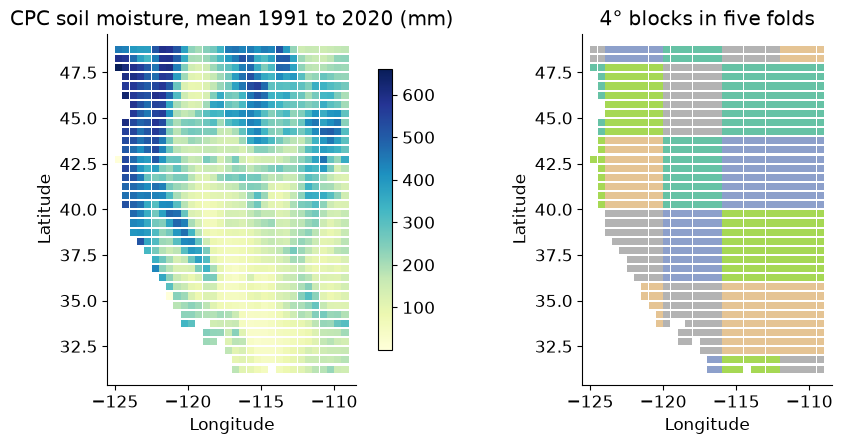

In [23]:
# Helper: the soil moisture field and the 4 degree blocks.
def plot_blocks():
    fold = np.zeros(len(cells), dtype=int)
    for k, (_, val) in enumerate(GroupKFold(5).split(cells, groups=block_labels(cells, 4))):
        fold[val] = k
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4.6))
    for ax, values, cmap, title in [(left, soil, "YlGnBu", "CPC soil moisture, mean 1991 to 2020 (mm)"), (right, fold, "Set2", "4° blocks in five folds")]:
        shown = ax.scatter(cells["lon"], cells["lat"], c=values, cmap=cmap, s=26, marker="s", linewidths=0)
        ax.set(xlabel="Longitude", ylabel="Latitude", title=title, aspect=1.25)
    fig.colorbar(left.collections[0], ax=left, shrink=0.8)
    plt.tight_layout()
    plt.show()


plot_blocks()

### Su turno (7): celdas aleatorias frente a bloques completos

**Pregunta:** ¿sigue cada bosque cartografiando la humedad del suelo en regiones que no ha visto?

`random_r2`, abajo, contiene el R² cuando las celdas se reparten al azar entre los pliegues. Calcule el R² de cada conjunto de variables cuando se apartan bloques completos de 4° y guarde ambos en el diccionario `block_r2`. R² = 1 es un mapa perfecto; R² = 0 no es mejor que la media en todas partes.

*Pista:* `pooled_r2(COORDINATES, GroupKFold(5), block_labels(cells, 4))`, y lo mismo con `CLIMATE`.

In [24]:
random_r2 = {"coordinates": pooled_r2(COORDINATES, KFold(5, shuffle=True, random_state=SEED)),
             "climate": pooled_r2(CLIMATE, KFold(5, shuffle=True, random_state=SEED))}

block_r2 = {"coordinates": None, "climate": None}   # replace each None

*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [25]:
block_r2_sol = {"coordinates": pooled_r2(COORDINATES, GroupKFold(5), block_labels(cells, 4)),
                "climate": pooled_r2(CLIMATE, GroupKFold(5), block_labels(cells, 4))}
if None in block_r2.values():
    block_r2 = None
check("block_r2", globals(), block_r2_sol, "call pooled_r2 with GroupKFold(5) and groups=block_labels(cells, 4).",
      measure=lambda d: [d["coordinates"], d["climate"]], tol=0.01)
ladder = pd.DataFrame({"coordinates": [random_r2["coordinates"]], "climate": [random_r2["climate"]]}, index=["random cells"])
for size in BLOCK_SIZES:
    groups = block_labels(cells, size)
    ladder.loc[f"{size} degree blocks"] = [pooled_r2(COORDINATES, GroupKFold(5), groups), pooled_r2(CLIMATE, GroupKFold(5), groups)]
ladder.round(2)

block_r2: not answered yet. Hint: call pooled_r2 with GroupKFold(5) and groups=block_labels(cells, 4).
  Using the reference result below.


,coordinates,climate
random cells,0.90,0.90
2 degree blocks,0.76,0.89
4 degree blocks,0.71,0.88
6 degree blocks,0.51,0.86


Lea la tabla de arriba abajo como una escalera de divisiones: cada fila pregunta por terreno más alejado de las celdas de entrenamiento. El viernes, la correlación del campo cayó a 0.40 a una distancia de 200 a 300 km, y aquí 4° equivalen a unos 300 a 440 km.

**Haga una pausa y discuta.**

- Los pliegues aleatorios califican igual a los dos bosques. ¿Cuál usaría para cartografiar una región sin estaciones? ¿Cómo lo habría sabido?
- Stock (2025, *Frontiers in Remote Sensing*) encontró que el tamaño de los bloques importaba más que su forma o que el número de pliegues. ¿Qué determina el tamaño de bloque adecuado para sus propios datos?

:::{dropdown} Puntos a destacar
Las coordenadas permiten al bosque interpolar entre vecinos, lo cual es útil dentro de una región muestreada e inútil fuera de ella. Los bloques deben ser al menos tan grandes como la distancia en la que el campo se mantiene correlacionado, y deben parecerse a la brecha entre sus datos de entrenamiento y los lugares donde va a predecir. Ninguna fila por sí sola da el score correcto: cada fila responde a una pregunta distinta.
:::

## Parte 3 (opcional). Evento: muchas estaciones, un sismo

*Datos:* 🖥️ Modelo y simulación · 🪨 Tierra sólida · 📈 Sismología

Esta tabla es **sintética**, para que conozcamos la verdad: 60 sismos registrados en 15 estaciones, donde el logaritmo de la aceleración máxima del suelo sigue la magnitud y la distancia, más una desviación compartida por todos los registros de un evento y una desviación propia de cada estación. Un catálogo real tendría la misma estructura, ya que un modelo de movimiento del suelo debe predecir el próximo sismo y nunca ha visto su desviación.

In [26]:
rng = np.random.default_rng(SEED)
n_events, n_stations = 60, 15
station_x, station_y = rng.uniform(0, 200, n_stations), rng.uniform(0, 200, n_stations)
station_term = rng.normal(0, 0.10, n_stations)
records = []
for event in range(n_events):
    magnitude = rng.uniform(4, 7)
    x, y = rng.uniform(0, 200), rng.uniform(0, 200)
    event_term = rng.normal(0, 0.30)
    for station in range(n_stations):
        distance = np.hypot(x - station_x[station], y - station_y[station]) + 5
        log_pga = 0.6 * magnitude - 1.5 * np.log10(distance) + event_term + station_term[station] + rng.normal(0, 0.15)
        records.append({"event": event, "magnitude": magnitude, "distance_km": distance, "log_pga": log_pga})
motions = pd.DataFrame(records)
X_event, y_event = motions[["magnitude", "distance_km"]], motions["log_pga"]
random_event_r2 = cross_val_score(forest, X_event, y_event, cv=KFold(5, shuffle=True, random_state=SEED)).mean()
print(f"{len(motions)} recordings, random folds: R² = {random_event_r2:.2f}")

900 recordings, random folds: R² = 0.87


### Su turno (8): mantener entero cada evento

**Pregunta:** ¿puede el bosque predecir el movimiento del suelo de un sismo que nunca ha visto?

Aparte eventos completos: todos los registros de un sismo van al entrenamiento o a la validación, nunca a ambos. Calcule el R² del bosque sobre estos pliegues y guárdelo en `event_r2`.

*Pista:* `cross_val_score(forest, X_event, y_event, cv=GroupKFold(5), groups=motions["event"]).mean()`.

In [27]:
event_r2 = None   # replace None with your expression

*Solución desarrollada abajo (haga clic en ⋯ para abrirla).*

In [28]:
event_r2_sol = cross_val_score(forest, X_event, y_event, cv=GroupKFold(5), groups=motions["event"]).mean()
check("event_r2", globals(), event_r2_sol, "use cv=GroupKFold(5) and pass groups=motions['event'].", tol=0.01)
print(f"Random folds {random_event_r2:.2f}, whole events {event_r2:.2f}")

event_r2: not answered yet. Hint: use cv=GroupKFold(5) and pass groups=motions['event'].
  Using the reference result below.
Random folds 0.87, whole events 0.65


La magnitud es idéntica en todos los registros de un evento, así que con pliegues aleatorios el bosque reconoce el evento y recuerda su desviación. Al dejar fuera eventos completos, ese atajo desaparece. Las voladuras de cantera repetidas y las secuencias de réplicas crean la misma trampa para un clasificador, y así lo declara [3.5](3.5_multiclass_classification.ipynb) para las tablas de su tabla de clasificación (*leaderboard*): no traen identificador de evento por el cual agrupar.

## Parte 4. Elegir la división

Pregúntese qué comparten sus muestras y mantenga eso a un solo lado de la línea.

| Las muestras comparten | Por qué están correlacionadas | Cómo validar | scikit-learn |
|---|---|---|---|
| **Tiempo** | las muestras consecutivas comparten condiciones meteorológicas, estación del año y deriva | entrenar con el pasado, validar con el futuro | `TimeSeriesSplit` |
| **Ubicación** | las mediciones repetidas en una ubicación son casi copias | dejar fuera ubicaciones completas | `GroupKFold` |
| **Evento** | un sismo o una tormenta llega a muchos instrumentos | dejar fuera eventos completos | `GroupKFold` |
| **Región** | las ubicaciones cercanas están sobre el mismo campo suave | dejar fuera bloques tan grandes como la distancia de correlación | `GroupKFold` sobre etiquetas de bloque |
| **Clase rara y grupos** | un grupo entero puede caer en un pliegue sin casos positivos | dejar fuera grupos, con los casos raros repartidos entre los pliegues | `StratifiedGroupKFold` |

Esta tabla va acompañada de tres hábitos:

- **Mantenga separados entrenamiento, validación y prueba.** Use la validación cruzada dentro de los datos de entrenamiento para comparar modelos y configuraciones. Califique el conjunto de prueba una sola vez, al final.
- **Ponga un modelo de referencia junto a cada score** y use unidades físicas cuando pueda.
- **Desconfíe de dejar uno fuera (*leave-one-out*).** Cuesta un ajuste por muestra, y en datos correlacionados cada muestra dejada fuera conserva a sus vecinas en el entrenamiento, así que es la división mezclada en su versión más optimista.

**Su proyecto.** ¿Qué fila corresponde a sus datos? ¿Qué significaría el score con la división que piensa usar? Lleve su respuesta al taller de auditoría de datos del lun 16 nov.

## Parte 5 (opcional). Una barra de error que respeta la correlación

«12 mm» también es una estimación. El *bootstrap* remuestrea los errores de validación y obtiene un intervalo a partir de su dispersión. Remuestrear errores individuales supone que son independientes. Estos errores no lo son, ya que las muestras vecinas comparten la mayor parte de su ventana, así que también remuestreamos bloques de 12 muestras (60 días).

In [29]:
errors = np.concatenate([np.abs(y_time[v] - RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1).fit(X_time[f], y_time[f]).predict(X_time[v]))
                         for f, v in future.split(X_time)])
draw = np.random.default_rng(0)
single = [draw.choice(errors, len(errors)).mean() for _ in range(2000)]
block_length = 12
n_blocks = int(np.ceil(len(errors) / block_length))
blocked = [np.concatenate([errors[s:s + block_length] for s in draw.integers(0, len(errors) - block_length + 1, n_blocks)])[:len(errors)].mean() for _ in range(2000)]
print(f"Mean error {errors.mean():.1f} mm")
print(f"95% interval, single errors: {np.percentile(single, 2.5):.1f} to {np.percentile(single, 97.5):.1f} mm")
print(f"95% interval, 60-day blocks: {np.percentile(blocked, 2.5):.1f} to {np.percentile(blocked, 97.5):.1f} mm")

Mean error 12.4 mm
95% interval, single errors: 12.0 to 12.8 mm
95% interval, 60-day blocks: 11.1 to 13.6 mm


**A continuación.** [3.9](3.9_ensemble_learning.ipynb) combina modelos y [3.10](3.10_autoML.ipynb) deja que una búsqueda elija entre ellos. Ambos usan la comparación justa que usted construyó aquí.

## Sus respuestas a las preguntas de discusión

Para las preguntas de **Haga una pausa y discuta** de las Partes 1 y 2 (tres series), escriba abajo unas frases por pregunta. Use sus propios números.

*Sus respuestas:*

## Reflexione sobre esta tarea

Como en cada tarea de este curso ([1.8](../Chapter1-GettingStarted/1.8_ai_in_your_workflow.md)), unas frases para cada pregunta:

1. **¿Qué aprendió en este ejercicio?** Nombre la idea científica o técnica, con un ejemplo de su propio trabajo en este notebook.
2. **¿Qué aprendió al interactuar con agentes o chatbots?** Diga qué preguntó, qué hizo bien la herramienta, qué hizo mal y cómo se dio cuenta.
3. **¿Qué sugeriría para mejorar esta tarea de modo que cumpla sus objetivos de aprendizaje?** Sea concreto.

**Declaración de uso de IA.** Una o dos frases: qué herramientas usó, para qué y qué verificó.

*Sus tres respuestas y su declaración:*

## Entrega a más tardar el lunes 16 de noviembre a las 23:59

Cambie el nombre de su notebook a `3.8_robust_training_UWNETID.ipynb`, elija Kernel, Restart Kernel and Run All Cells, guarde y súbalo a la tarea de Canvas **"Lab 3.8: robust training"**. Se califica: las tareas 1 a 7 hechas por usted (la tarea 8 es opcional), que el notebook se ejecute de principio a fin, sus respuestas a las preguntas de discusión y su reflexión.